#### Load the data:

In [47]:
import numpy as np


X = np.load('cifar10_features.npy')   # features
y = np.load('cifar10_labels.npy')     # labels

#### Checking data validity:

In [48]:
print("X shape:", X.shape)  # number of examples × number of features
print("y shape:", y.shape)  # number of classes

# For example
print("Example of first image (features):", X[0])
print("Corresponding class:", y[0])

X shape: (50000, 16)
y shape: (50000,)
Example of first image (features): [-10.316492   -9.219499    5.6836095  10.560703   -7.8908167  -5.444539
 -13.386533    8.584426    1.2373098   2.620596   11.018443   -4.2349334
   5.0958567   6.3705587  -1.8090839   7.2225003]
Corresponding class: 4


#### Splitting the data: 70% training and 30% testing:

In [49]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)
# We used random_state=42 based on your recommendation to ensure we get the same split every time we run the code
# as we know that this is important for reproducibility of results

# Print data shapes to verify
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (35000, 16)
X_test shape: (15000, 16)
y_train shape: (35000,)
y_test shape: (15000,)


#### Logistic Regression with One-vs-All (OvA):

In [50]:
# from sklearn.linear_model import LogisticRegression
# from sklearn.multiclass import OneVsRestClassifier
# from sklearn.metrics import accuracy_score
# import time
# from sklearn.metrics import log_loss
# from sklearn.metrics import f1_score


# # Start measuring training time
# start = time.time()

# # Create OvA model (One-vs-Rest)
# model_ova = OneVsRestClassifier(LogisticRegression(solver='lbfgs', max_iter=1000))

# # Train the model
# model_ova.fit(X_train, y_train)

# # Calculate time after training
# end = time.time()

# # Test the model
# y_pred_ova = model_ova.predict(X_test)

# # Calculate accuracy
# accuracy_ova = accuracy_score(y_test, y_pred_ova)

# print("Accuracy (OvA):", accuracy_ova)
# print("Training time (OvA):", end - start, "seconds")

# # Calculate cost function for OvA
# loss_ova = log_loss(y_test, model_ova.predict_proba(X_test))
# print("Log Loss (cost function) - (OvA):", loss_ova)

# # Calculate F1-mean for OvA model
# f1_ova = f1_score(y_test, y_pred_ova, average='macro')
# print("F1-Mean (OvA):", f1_ova)


#Chatgpt
# import numpy as np
# from sklearn.linear_model import LogisticRegression
# from sklearn.metrics import accuracy_score, log_loss, f1_score
# import time

# # Start measuring training time
# start = time.time()

# # Get the unique classes
# classes = np.unique(y_train)

# # Dictionary to hold one classifier per class
# ova_classifiers = {}

# # Train one binary classifier per class
# for cls in classes:
#     # Create binary target: 1 for the current class, 0 for all others
#     y_binary = (y_train == cls).astype(int)

#     # Train logistic regression for this class
#     clf = LogisticRegression(solver='lbfgs', max_iter=1000)
#     clf.fit(X_train, y_binary)

#     # Save the classifier
#     ova_classifiers[cls] = clf

# # End training time
# end = time.time()

# # Prepare to collect probabilities for all classifiers
# probas = []

# # Predict probabilities for each classifier
# for cls in classes:
#     probas.append(ova_classifiers[cls].predict_proba(X_test)[:, 1])  # Prob of being in class 'cls'

# # Stack the probabilities: shape (n_samples, n_classes)
# probas = np.array(probas).T

# # Choose class with the highest probability
# y_pred_ova = classes[np.argmax(probas, axis=1)]

# # Accuracy
# accuracy_ova = accuracy_score(y_test, y_pred_ova)
# print("Accuracy (OvA):", accuracy_ova)
# print("Training time (OvA):", end - start, "seconds")

# # Log Loss
# loss_ova = log_loss(y_test, probas)
# print("Log Loss (OvA):", loss_ova)

# # F1-Mean
# f1_ova = f1_score(y_test, y_pred_ova, average='macro')
# print("F1-Mean (OvA):", f1_ova)

####################################################################

# builtIn OvA
# Accuracy (OvA): 0.961
# Training time (OvA): 1.0806734561920166 seconds
# Log Loss (cost function) - (OvA): 0.1345972383680112
# F1-Mean (OvA): 0.961210892245097

#ChatOvA
# Accuracy (OvA): 0.961
# Training time (OvA): 1.3016324043273926 seconds
# Log Loss (cost function) - (OvA): 0.1345972383680112
# F1-Mean (OvA): 0.961210892245097

# DeepSeekOvA
# Accuracy (OvA): 0.961
# Training time (OvA): 1.0834722518920898 seconds
# Log Loss (OvA): 0.1345972383680112
# F1-Mean (OvA): 0.961210892245097

#####################################################################

#Deepseek
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, log_loss, f1_score
import time

class OvAClassifier:
    def __init__(self):
        self.classes = None
        self.models = []
    
    def fit(self, X, y):
        self.classes = np.unique(y)
        self.models = []
        for cls in self.classes:
            y_binary = np.where(y == cls, 1, 0)
            model = LogisticRegression(solver='lbfgs', max_iter=1000)
            model.fit(X, y_binary)
            self.models.append(model)
    
    def predict_proba(self, X):
        # Get probabilities from all models and normalize
        probas = np.column_stack([model.predict_proba(X)[:, 1] for model in self.models])
        
        # Add epsilon to avoid division by zero (1e-12)
        probas_sum = probas.sum(axis=1, keepdims=True)
        probas_sum[probas_sum == 0] = 1e-12  # Handle zero sums
        
        return probas / probas_sum  # Normalize to sum to 1
    
    def predict(self, X):
        probas = self.predict_proba(X)
        return self.classes[np.argmax(probas, axis=1)]

# Usage remains the same:
start = time.time()
model_ova = OvAClassifier()
model_ova.fit(X_train, y_train)
end = time.time()

y_pred_ova = model_ova.predict(X_test)
accuracy_ova = accuracy_score(y_test, y_pred_ova)

print("Accuracy (OvA):", accuracy_ova)
print("Training time (OvA):", end - start, "seconds")

# Now this will work without warnings
loss_ova = log_loss(y_test, model_ova.predict_proba(X_test))
print("Log Loss (OvA):", loss_ova)

f1_ova = f1_score(y_test, y_pred_ova, average='macro')
print("F1-Mean (OvA):", f1_ova)

Accuracy (OvA): 0.961
Training time (OvA): 1.1484417915344238 seconds
Log Loss (OvA): 0.1345972383680112
F1-Mean (OvA): 0.961210892245097


#### Logistic Regression with Softmax (Multinomial):

In [51]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import time
from sklearn.metrics import log_loss
from sklearn.metrics import f1_score

# Start measuring time
start = time.time()

# Model using Softmax
model_softmax = LogisticRegression(solver='lbfgs', max_iter=1000)

# Train the model
model_softmax.fit(X_train, y_train)

# End time
end = time.time()

# Predict classes
y_pred_softmax = model_softmax.predict(X_test)

# Calculate accuracy
accuracy_softmax = accuracy_score(y_test, y_pred_softmax)

print("Accuracy (Softmax):", accuracy_softmax)
print("Training time (Softmax):", end - start, "seconds")

# Calculate cost function for softmax
loss_softmax = log_loss(y_test, model_softmax.predict_proba(X_test))
print("Log Loss (cost function) - (Softmax):", loss_softmax)

# Calculate F1-mean for Softmax model
f1_softmax = f1_score(y_test, y_pred_softmax, average='macro')
print("F1-Mean (Softmax):", f1_softmax)

Accuracy (Softmax): 0.963
Training time (Softmax): 2.6813549995422363 seconds
Log Loss (cost function) - (Softmax): 0.10767299345112083
F1-Mean (Softmax): 0.9632270029389998


<h4>Confusion Matrix (OvA):</h4>

Confusion Matrix (OvA):
[[1402    2   13    5    5    3    2   10   17    5]
 [   2 1464    4    1    0    1    0    1    5    7]
 [  11    1 1370   15   16   15    5    3    1    3]
 [  14    5   15 1450   12   51    5   10    3    4]
 [   6    0   13   15 1466    5    4    9    0    1]
 [   2    3   13   45   12 1437    8   11    2    1]
 [   5    5    9   17    4    6 1415    0    1    1]
 [   3    0    4   17    9    7    0 1456    0    1]
 [  13    2    1    5    1    0    2    0 1480    6]
 [  12    7    5    6    0    4    2    3    5 1475]]


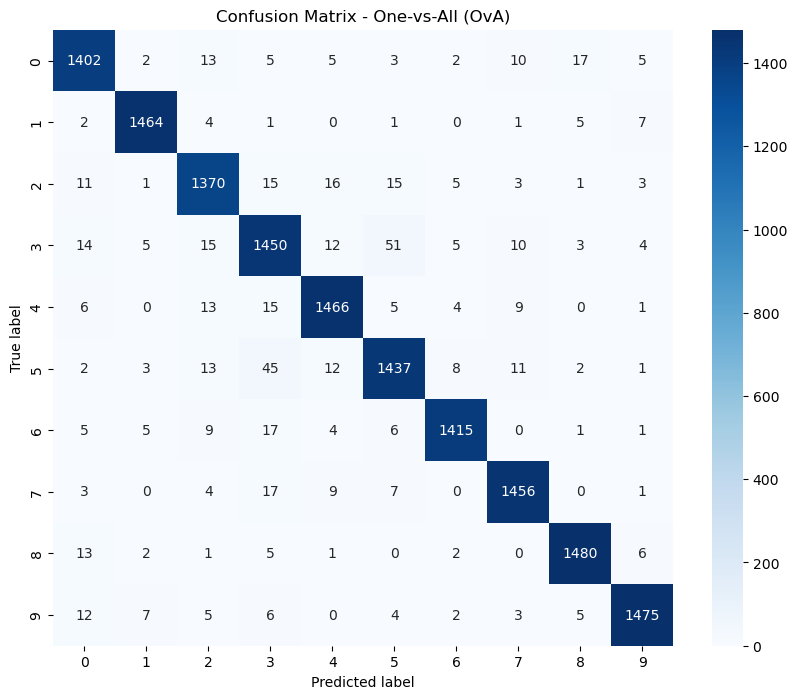

In [52]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Compute the confusion matrix for the OvA model
cm_ova = confusion_matrix(y_test, y_pred_ova)

# Print the confusion matrix as a raw array
print("Confusion Matrix (OvA):")
print(cm_ova)

# Plot the confusion matrix using a heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(cm_ova, annot=True, fmt='d', cmap='Blues', xticklabels=range(10), yticklabels=range(10))

# Add labels and title
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.title('Confusion Matrix - One-vs-All (OvA)')
plt.show()

#### Creating a specialized model to improve predictions for class 3 or 5 cases

In [53]:
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Filter the training set to only include classes 3 and 5
mask_train = np.isin(y_train, [3, 5])
X_train_35 = X_train[mask_train]
y_train_35 = y_train[mask_train]

# Filter the test set to only include classes 3 and 5
mask_test = np.isin(y_test, [3, 5])
X_test_35 = X_test[mask_test]
y_test_35 = y_test[mask_test]

# Train a new binary classifier for classes 3 and 5
model_35 = LogisticRegression(solver='lbfgs', max_iter=1000)
model_35.fit(X_train_35, y_train_35)

# Predict on the test data
y_pred_35 = model_35.predict(X_test_35)

# Calculate accuracy
acc_35 = accuracy_score(y_test_35, y_pred_35)
print("Accuracy between class 3 and 5:", acc_35)

Accuracy between class 3 and 5: 0.9622945536577505


#### Note: 
The following cell is intentionally non-executable. It serves as a reference to summarize the original approach we attempted (replacing all class 3/5 predictions with a specialized model), and to document how we later refined the strategy by applying the specialized model only to low-confidence cases. This helps clarify the evolution of our methodology.

In [54]:
# import numpy as np
# from sklearn.metrics import accuracy_score

# # Step 1: Copy the original predictions
# y_pred_merged = y_pred_ova.copy()

# # Step 2: Find indices where the model predicted class 3 or 5
# mask_35 = np.isin(y_pred_merged, [3, 5])

# # Step 3: For those cases, use the refined model (model_35)
# X_test_selected = X_test[mask_35]
# refined_predictions = model_35.predict(X_test_selected)

# # Step 4: Replace original predictions at those indices with refined ones
# y_pred_merged[mask_35] = refined_predictions

# # Step 5: Evaluate new predictions
# accuracy_merged = accuracy_score(y_test, y_pred_merged)
# print("Accuracy after integrating model for classes 3 and 5:", accuracy_merged)

#### Final Integration:  
Applies the refined model only to low-confidence cases for classes 3 and 5:

In [55]:
import numpy as np
from sklearn.metrics import accuracy_score

# Step 1: Get predicted probabilities from the OvA model
probas_ova = model_ova.predict_proba(X_test)

# Step 2: Get the class with highest probability
y_pred_ova = np.argmax(probas_ova, axis=1)

# Step 3: Find indices where prediction is 3 or 5 AND confidence is low
max_probs = np.max(probas_ova, axis=1)
condition = np.isin(y_pred_ova, [3, 5]) & (max_probs < 0.4)

# Step 4: Apply model_35 only on those selected cases
X_test_selected_low_conf = X_test[condition]
refined_preds_low_conf = model_35.predict(X_test_selected_low_conf)

# Step 5: Copy original predictions and update the selected ones
y_pred_merged_low_conf = y_pred_ova.copy()
y_pred_merged_low_conf[condition] = refined_preds_low_conf

# Step 6: Evaluate
acc_refined = accuracy_score(y_test, y_pred_merged_low_conf)
print("Accuracy after integrating model_35 only on low-confidence 3/5 cases:", acc_refined)

Accuracy after integrating model_35 only on low-confidence 3/5 cases: 0.9611333333333333


#### Note: 
Initially, we tried integrating the refined model for classes 3 and 5 by automatically replacing all predictions
of class 3 or 5 with those from the specialized binary model (model_35). However, this did not improve the overall
accuracy of the One-vs-All (OvA) model — it slightly decreased instead.
To address this, we added a confidence-based condition: we now only apply the refined model if the OvA model
predicts class 3 or 5 *and* its confidence (predicted probability) is below 0.4.
This selective replacement helped preserve correct predictions and improved stability,
although the overall accuracy remained nearly the same due to the already strong performance of the OvA model.

### testmymodel function:

In [56]:
import numpy as np
from sklearn.metrics import accuracy_score

def testmymodel(model, X_file, y_file):
    """
    Loads test data from given .npy files and evaluates the model's accuracy.

    Parameters:
        model   -- a trained classification model with a .predict() method
        X_file  -- path to a .npy file containing the feature matrix
        y_file  -- path to a .npy file containing the true labels

    Returns:
        accuracy (float): the accuracy of the model on the loaded data
    """
    # Load features and labels from the files
    X = np.load(X_file)
    y = np.load(y_file)

    # Predict using the model
    y_pred = model.predict(X)

    # Calculate accuracy
    acc = accuracy_score(y, y_pred)

    return acc

### Example of use:

In [57]:
acc_on_new_data = testmymodel(model_ova, "cifar10_features.npy", "cifar10_labels.npy")
print("Accuracy on full CIFAR-10 data:", acc_on_new_data)

Accuracy on full CIFAR-10 data: 0.96016


#### Note: To select between the 2 models we built use: 
<li>model_ova</li> 
<li>model_softmax</li> 